# ML

# Lab03

- Bước 1: tính định lý Bayes bằng tay, không cần thư viện học máy.

- Bước 2: đọc kho tin nhắn va bien văn bản thành bảng số.

- Bước 3: huan luyen bo loc thu rac va cham điem no.

- Bước 4: tự cài Naive Bayes trên một kho nhỏ để thấy vấn đề số không

- Bước 5: Naive Bayes cho số liệu liên tục, đặt cạnh hồi quy logistic

Tính bằng Python

In [2]:
# d1_bayes_tay.py - Tính định lý Bayes bằng tay

def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):


  tu_so = kha_nang * tien_nghiem
  mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
  return tu_so / mau_so

print("Vi du 1: xet nghiem benh")
print(" Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f" Duong tinh thi kha nang co benh that = {p:.4f}")
print()

# Giữ nguyên chất Lượng xét nghiệm, chủ đổi tỷ Lệ mắc bệnh
print("Cung xet nghiem do, doi ty le mac benh:")
print(" Ty le mac benh   Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
  print(f"{ty_le:6.3f}     {bayes(ty_le, 0.99, 0.01):.4f}")

print()

print("Vi du 2: hai day chuyen san xuat")
print(" Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print(" Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")
# Ở đây "A đúng" nghĩa Là sản pham đến từ dây B
p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f" Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f" Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f" Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f" Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")

Vi du 1: xet nghiem benh
 Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
 Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
 Ty le mac benh   Hau nghiem khi duong tinh
 0.001     0.0902
 0.010     0.5000
 0.050     0.8390
 0.100     0.9167
 0.500     0.9900

Vi du 2: hai day chuyen san xuat
 Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
 Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
 Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
 Day A: 800 san pham, 8 cai loi
 Day B: 200 san pham, 10 cai loi
 Ty le tu day B = 10.0 / 18.0 = 0.5556


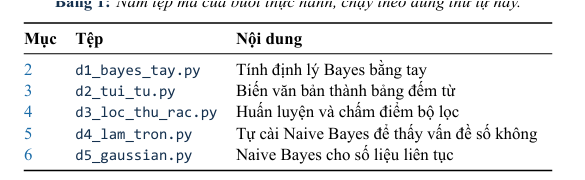

Làm bằng scikit‐learn

In [4]:
# d2_tui_tu.py - Biến văn bản thành bảng đếm từ
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("tin_nhan.csv")

print("Kich thuoc bang:", df.shape)
print()
print("So tin theo nhan (1 la rac, 0 la thuong):")
print(df["la_rac"].value_counts())
print()
print("Ty le tin rac:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhan dau tien:")
for i in range(3):
  print(f" [{df.la_rac[i]}] {df.noi_dung[i]}")
print()

# token_pattern mặc định của scikit-Learn bỏ mất từ một ký tự,
# nên ta chủ định tách từ bằng khoảng trắng cho đơn giản.
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])

print("Kich thuoc bang dem tu:", X.shape)
print("So tu trong tu dien:", len(vec.vocabulary_))
print()

# Đếm tổng số Lần xuất hiện của từng từ, tách theo hai Lớp
dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]

print("Muoi tu xuat hien nhieu nhat trong tin rac:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Muoi tu xuat hien nhieu nhat trong tin thuong:")
print(tong.sort_values("thuong", ascending=False).head(10))

Kich thuoc bang: (300, 2)

So tin theo nhan (1 la rac, 0 la thuong):
la_rac
0    180
1    120
Name: count, dtype: int64

Ty le tin rac: 0.4

Ba tin nhan dau tien:
 [0] a có cho gửi
 [0] nhanh gửi tập liệu cho tài
 [1] click ngay cáo sốc

Kich thuoc bang dem tu: (300, 40)
So tu trong tu dien: 40

Muoi tu xuat hien nhieu nhat trong tin rac:
       thuong  rac
click       5   28
mãi         3   26
hot         8   25
ngay        5   24
nhanh       3   24
trúng       5   24
vàng        3   23
miễn        4   23
phí         4   23
giảm        3   23

Muoi tu xuat hien nhieu nhat trong tin thuong:
        thuong  rac
mình        41   10
gửi         39    8
liệu        39   13
thầy        38    6
có          37   12
tài         37    4
họp         37   10
em          36   12
trường      35    6
a           35    8


Công thức Naive Bayes

Huấn luyện và chấm điểm

In [6]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix,
precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("So tin de hoc:", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()

mo_hinh = MultinomialNB(alpha=1.0)

mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f" TN = {tn:2d} thu thuong duoc giu dung")
print(f" FP = {fp:2d} thu thuong bi xoa nham")
print(f" FN = {fn:2d} thu rac lot luoi")
print(f" TP = {tp:2d} thu rac bi chan dung")
print()

print(f"Accuracy = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall = {recall_score(y_test, y_pred):.4f}")

print()

# Thu bộ Lọc trên vài tin nhắn tự gõ
tin_moi = [
          "trung thuong khuyen mai nhanh tay click ngay",
          "hop nhom bao cao chieu mai phong 305",
          "ban gui giup em tai lieu bai tap nhe",
]

X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]

print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
  nhan = "RAC" if p >= 0.5 else "thuong"
  print(f" [{nhan:6s}] p = {p:.4f} <- {tin}")

So tin de hoc: 225
So tin de kiem tra: 75

Ma tran nham lan
 TN = 45 thu thuong duoc giu dung
 FP =  0 thu thuong bi xoa nham
 FN =  5 thu rac lot luoi
 TP = 25 thu rac bi chan dung

Accuracy = 0.9333
Precision = 1.0000
Recall = 0.8333

Thu tren ba tin nhan tu go:
 [RAC   ] p = 0.9978 <- trung thuong khuyen mai nhanh tay click ngay
 [thuong] p = 0.4000 <- hop nhom bao cao chieu mai phong 305
 [thuong] p = 0.2379 <- ban gui giup em tai lieu bai tap nhe


Tự cài đặt để thấy tận mắt

In [10]:
from collections import Counter

kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]

tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
# In thành nhiều dòng, mỗi dòng 9 từ, để không tràn ra ngoài khung
for i in range(0, V, 9):
  print(" "+ " ".join(tu_dien[i:i + 9]))
print()

# Đếm số Lần mỗi từ xuất hiện trong từng Lớp
dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
  for t in cau.split():
    dem[nhan][t] += 1
    tong[nhan] += 1

print("So lan xuat hien cua tung tu")
print(f" {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
  print(f" {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()

def xac_suat(tu, nhan, alpha):
  return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)

def diem(cau, nhan, alpha):
  p = 0.5
  # hai Lop can bang nen tien nghiem bang nhau
  for t in cau.split():
    if t in tu_dien:
      p *= xac_suat(t, nhan, alpha)
  return p

cau_thu = "trung thuong bai tap"
print(f"tin nhan thu: \"{cau_thu}\"")
print("tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")

print()

for alpha in [0.0, 1.0]:
  d_rac = diem(cau_thu, 1, alpha)
  d_thuong = diem(cau_thu, 0, alpha)
  ket = "rac" if d_rac > d_thuong else "thuong"
  print(f"alpha = {alpha}")
  print(f" diem lop rac = {d_rac:.10f}")
  print(f" diem lop thuong = {d_thuong:.10f}")
  print(f" ket luan = {ket}")
  print()

print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")

Tu dien co 18 tu:
 bai chieu click gia giam gui hop khuyen lieu
 mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu
 tu             rac  thuong
 bai              0       1
 chieu            0       1
 click            1       0
 gia              1       0
 giam             1       0
 gui              0       1
 hop              0       1
 khuyen           1       0
 lieu             0       1
 mai              1       2
 ngay             1       0
 nhom             0       2
 nop              0       1
 tai              0       1
 tap              0       1
 thay             0       1
 thuong           2       0
 trung            2       0

tin nhan thu: "trung thuong bai tap"
tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
 diem lop rac = 0.0000000000
 diem lop thuong = 0.0000000000
 ket luan = thuong

alpha = 1.0
 diem lop rac = 0.0000073212
 diem lop thuong = 0.0000021656
 ket luan = rac

Khong lam tron, CA HAI diem deu bang 0 nen mo 

So với hSo với hồi quy logistic trên cùng dữ liệuồi quy logistic trên cùng dữ liệu

In [12]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# Đọc trực tiếp từ thư mục gốc Colab
df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai mô hình, cùng dữ Liệu, cùng cách chia, nên so sánh mới công bằng
for ten, mo_hinh in [("Naive Bayes ", GaussianNB()),
                    ("Hoi quy logistic", LogisticRegression())]:
  mo_hinh.fit(X_train, y_train)

  acc = accuracy_score(y_test, mo_hinh.predict(X_test))
  print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(X_train, y_train)

print("Nhung gi Naive Bayes hoc duoc")
print(f" {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lop 0 (rot) ", "Lop 1 (qua) "]):
  tb = gnb.theta_[i]
  dl = gnb.var_[i] ** 0.5
  print(f" {ten_lop} trung binh {tb[0]:10.2f} {tb[1]:14.2f}")
  print(f" {'':12s} do lech {dl[0]:10.2f} {dl[1]:14.2f}")
print()

ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Ty le tung lop trong tap hoc: {ty_le}")
print()

# Dự đoán cho vài sinh viên giả định
ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                        "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Du doan cho bon ban moi:")
print(f" {'gio on':>8s} {'diem GK':>9s} {'P(qua mon)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
  print(f" {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")

Naive Bayes : accuracy = 0.9000
Hoi quy logistic: accuracy = 0.9000

Nhung gi Naive Bayes hoc duoc
                      gio_on   diem_giua_ky
 Lop 0 (rot)  trung binh       8.18           3.99
              do lech       5.29           1.92
 Lop 1 (qua)  trung binh      20.03           6.70
              do lech       5.81           1.50

Ty le tung lop trong tap hoc: 0.4111, 0.5889

Du doan cho bon ban moi:
   gio on   diem GK   P(qua mon)
        5       4.0       0.0137
       13       6.0       0.6550
       20       7.0       0.9855
       28       9.0       0.9999


# BÀI TẬP

Bài tập 1: Bayes với ba nguyên nhân


Một lớp có ba nhóm sinh viên: 50 phần trăm học đều, 30 phần trăm học dồn, 20 phần trăm
ít học. Tỷ lệ qua môn của ba nhóm lần lượt là 0.95, 0.70 và 0.30.
Gặp một bạn đã qua môn. Tính xác suất bạn đó thuộc từng nhóm. Ba con số cộng lại phải
bằng 1, hãy dùng điều đó để tự kiểm tra.
Gợi ý, mở rộng hàm bayes trong d1_bayes_tay.py cho ba nhánh thay vì hai.

In [14]:
def bayes_ba_nhanh(tien_nghiem, kha_nang):
    tu_so  = [p * k for p, k in zip(tien_nghiem, kha_nang)]
    mau_so = sum(tu_so)
    return [t / mau_so for t in tu_so], mau_so


tien = [0.5, 0.3, 0.2]
kha  = [0.95, 0.70, 0.30]              # P(qua | hoc deu / don / it)

hau, p_qua = bayes_ba_nhanh(tien, kha)
print(f"P(qua mon)        = {p_qua:.4f}")
print(f"P(hoc deu  | qua) = {hau[0]:.4f}")
print(f"P(hoc don  | qua) = {hau[1]:.4f}")
print(f"P(it hoc   | qua) = {hau[2]:.4f}")
print(f"Tong hau nghiem   = {sum(hau):.4f}")
print()

# Kiem tra bang cach dem tren 1000 sinh vien
deu, don, it = 500, 300, 200
q_deu = deu * 0.95
q_don = don * 0.70
q_it  = it  * 0.30
tong  = q_deu + q_don + q_it
print("Kiem tra tren 1000 sinh vien:")
print(f"  Hoc deu: {deu} nguoi, {q_deu:.0f} qua mon")
print(f"  Hoc don: {don} nguoi, {q_don:.0f} qua mon")
print(f"  It hoc : {it}  nguoi, {q_it:.0f} qua mon")
print(f"  P(deu|qua) = {q_deu/tong:.4f}, "
      f"P(don|qua) = {q_don/tong:.4f}, "
      f"P(it|qua) = {q_it/tong:.4f}")

P(qua mon)        = 0.7450
P(hoc deu  | qua) = 0.6376
P(hoc don  | qua) = 0.2819
P(it hoc   | qua) = 0.0805
Tong hau nghiem   = 1.0000

Kiem tra tren 1000 sinh vien:
  Hoc deu: 500 nguoi, 475 qua mon
  Hoc don: 300 nguoi, 210 qua mon
  It hoc : 200  nguoi, 60 qua mon
  P(deu|qua) = 0.6376, P(don|qua) = 0.2819, P(it|qua) = 0.0805


Bài tập 2: Từ nào tố cáo mạnh nhất


Huấn luyện MultinomialNB trên toàn bộ 300 tin nhắn.
Dùng thuộc tính
feature_log_prob_ để tính hiệu giữa hai lớp cho từng từ, rồi in ra 5 từ tố cáo tin
rác mạnh nhất và 5 từ cho thấy tin thường mạnh nhất.
Gợi ý, feature_log_prob_ là một mảng hai dòng, dòng 0 cho lớp 0 và dòng 1 cho lớp 1.
Lấy mo_hinh.feature_log_prob_[1]‐ mo_hinh.feature_log_prob_[0] rồi sắp xếp.

In [20]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# Đã sửa lại đường dẫn để đọc trực tiếp từ thư mục gốc Colab
df  = pd.read_csv("tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X   = vec.fit_transform(df["noi_dung"])
y   = df["la_rac"]

mo_hinh = MultinomialNB(alpha=1.0).fit(X, y)
tu      = vec.get_feature_names_out()

# Dòng 0: lớp thường, dòng 1: lớp rác
chenh = mo_hinh.feature_log_prob_[1] - mo_hinh.feature_log_prob_[0]
bang  = pd.DataFrame({"tu": tu, "chenh": chenh}).sort_values("chenh", ascending=False)

print("5 tu to cao tin RAC manh nhat:")
print(bang.head(5).to_string(index=False))
print()
print("5 tu to cao tin THUONG manh nhat:")
print(bang.tail(5).to_string(index=False))

5 tu to cao tin RAC manh nhat:
   tu    chenh
  mãi 3.203435
  tay 2.905600
 ngay 2.661837
 miễn 2.479516
trúng 2.374155

5 tu to cao tin THUONG manh nhat:
   tu     chenh
  báo -2.274074
phòng -2.274074
  bài -2.294553
   em -2.561756
  lớp -2.612187


Bài tập 3: Đổi tham số làm trơn


Chạy lại bộ lọc với alpha lần lượt bằng 0.001, 0.1, 1.0, 10.0 và 100.0. Với mỗi giá trị, in
ra accuracy, precision và recall trên tập kiểm tra.
Nhận xét một câu: alpha lớn quá thì chuyện gì xảy ra, và vì sao? Gợi ý cho phần giải thích,
alpha rất lớn làm mọi xác suất từ xích lại gần nhau.

In [23]:
# bai3.py
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.naive_bayes import MultinomialNB

# Sửa đường dẫn file đọc trực tiếp từ thư mục gốc Colab
df  = pd.read_csv("tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X   = vec.fit_transform(df["noi_dung"])
y   = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

print(f"{'alpha':>8s} {'acc':>8s} {'prec':>8s} {'recall':>8s}")
for a in [0.001, 0.1, 1.0, 10.0, 100.0]:
    m = MultinomialNB(alpha=a).fit(X_train, y_train)
    pred = m.predict(X_test)
    print(f"{a:>8.3f} {accuracy_score(y_test, pred):>8.4f} "
          f"{precision_score(y_test, pred):>8.4f} "
          f"{recall_score(y_test, pred):>8.4f}")

   alpha      acc     prec   recall
   0.001   0.9467   1.0000   0.8667
   0.100   0.9467   1.0000   0.8667
   1.000   0.9467   1.0000   0.8667
  10.000   0.9467   1.0000   0.8667
 100.000   0.9467   1.0000   0.8667


Bài tập 4: Tự viết bộ lọc không dùng thư viện


Dựa vào d4_lam_tron.py, viết một bộ lọc hoàn chỉnh cho toàn bộ 300 tin nhắn. Tự đếm
từ, tự làm trơn, tự tính điểm cho hai lớp bằng tổng loga thay vì tích.
Chia dữ liệu bằng train_test_split với random_state=17 rồi so accuracy của bộ lọc tự
viết với MultinomialNB. Hai con số phải rất gần nhau. Nếu lệch nhiều thì có lỗi ở đâu đó,
hãy tìm ra.

In [24]:
# bai4.py
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB


class NaiveBayesTuViet:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.log_prior_, self.log_like_ = {}, {}
        for c in self.classes_:
            mask = (y == c)
            Xc   = X[mask]
            self.log_prior_[c] = np.log(mask.mean())
            dem  = Xc.sum(axis=0) + self.alpha
            tong = Xc.sum() + self.alpha * X.shape[1]
            self.log_like_[c] = np.log(dem / tong)
        return self

    def predict(self, X):
        X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
        diem = {c: self.log_prior_[c] + X @ self.log_like_[c] for c in self.classes_}
        return np.array([max(diem, key=lambda c: diem[c][i])
                         for i in range(X.shape[0])])


# Sửa đường dẫn file đọc trực tiếp từ thư mục gốc Colab
df  = pd.read_csv("tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X   = vec.fit_transform(df["noi_dung"])
y   = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

tv = NaiveBayesTuViet(alpha=1.0).fit(X_train, y_train)
sk = MultinomialNB(alpha=1.0).fit(X_train, y_train)

print(f"Tu viet       : acc = {accuracy_score(y_test, tv.predict(X_test)):.4f}")
print(f"MultinomialNB : acc = {accuracy_score(y_test, sk.predict(X_test)):.4f}")

Tu viet       : acc = 0.9467
MultinomialNB : acc = 0.9467


Bài tập 5: Chọn sai biến thể Naive Bayes


Chạy MultinomialNB trên bộ dữ liệu sinh viên với hai cột gio_on và diem_giua_ky. In ra
accuracy rồi so với GaussianNB ở mục 6.
Chương trình có báo lỗi không? Con số accuracy ra bao nhiêu? Giải thích vì sao dùng
MultinomialNB ở đây là sai về nguyên tắc, dù nó vẫn chạy.

In [25]:
# bai5.py
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB, GaussianNB

# Sửa đường dẫn file đọc trực tiếp từ thư mục gốc Colab
df = pd.read_csv("sinh_vien.csv")
X  = df[["gio_on", "diem_giua_ky"]]
y  = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

try:
    m = MultinomialNB().fit(X_train, y_train)
    print(f"MultinomialNB : acc = {accuracy_score(y_test, m.predict(X_test)):.4f}")
except Exception as e:
    print("MultinomialNB loi:", e)

g = GaussianNB().fit(X_train, y_train)
print(f"GaussianNB    : acc = {accuracy_score(y_test, g.predict(X_test)):.4f}")

MultinomialNB : acc = 0.8000
GaussianNB    : acc = 0.9000


Bài tập 6: Lớp hiếm và xác suất tiên nghiệm


Từ bộ tin nhắn, tạo một bộ mới mất cân bằng nặng: giữ toàn bộ 180 tin thường nhưng chỉ
lấy 20 tin rác đầu tiên. Huấn luyện lại và chấm điểm.
In ra accuracy và recall của lớp rác. Nhận xét: accuracy có còn phản ánh đúng chất lượng
bộ lọc không? Gợi ý, dùng recall_score với pos_label=1, và nhớ lại cái bẫy accuracy ở
bài 2.

In [26]:
# bai6.py
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.naive_bayes import MultinomialNB

# Sửa đường dẫn file đọc trực tiếp từ thư mục gốc Colab
df  = pd.read_csv("tin_nhan.csv")
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X   = vec.fit_transform(df["noi_dung"])
y   = df["la_rac"]

# Giu 180 thuong, chi lay 20 rac dau tien  -> mat can bang nang
df_moi = pd.concat([
    df[df["la_rac"] == 0],
    df[df["la_rac"] == 1].head(20)
])
X_moi = vec.transform(df_moi["noi_dung"])
y_moi = df_moi["la_rac"]

print("Ty le rac trong tap moi:", round(y_moi.mean(), 4))

X_train, X_test, y_train, y_test = train_test_split(
    X_moi, y_moi, test_size=0.25, random_state=17, stratify=y_moi)

m = MultinomialNB(alpha=1.0).fit(X_train, y_train)
pred = m.predict(X_test)

print(f"Accuracy  = {accuracy_score(y_test, pred):.4f}")
print(f"Precision = {precision_score(y_test, pred, pos_label=1):.4f}")
print(f"Recall    = {recall_score(y_test, pred, pos_label=1):.4f}")

Ty le rac trong tap moi: 0.1
Accuracy  = 0.9800
Precision = 1.0000
Recall    = 0.8000
